# In-silico perturbation with dynamo's vector field

The dynamo backend of `ov.single.perturb` uses
`dynamo.pd.perturbation` to propagate a target-gene expression change
through a learned PCA vector field. The default `j_delta_x` method uses its analytical Jacobian:

$$\delta Y = J \cdot \delta X.$$

The per-cell, per-gene response and perturbation transition matrix are
returned as a `PerturbResult` for downstream analysis and visualization.
This tutorial uses dynamo's processed hematopoiesis reference data to
simulate knockout of the erythroid transcription factor **GATA1**.

This backend requires velocity-compatible data and a learned vector field,
or raw splicing/labeling measurements from which dynamo can estimate them.
`backend='auto'` selects dynamo when `adata.uns['VecFld_pca']` is present.
Choose a backend explicitly when selecting a different model.

## Requirements

Install OmicVerse and the optional dynamo backend in the same Python environment:

```bash
python -m pip install 'dynamo-release==1.5.3' 'numpy<2'
```

The examples use dynamo-release 1.5.3. The processed dataset is downloaded
on its first use; the raw-data example requires a separately downloaded file.

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import omicverse as ov

ov.utils.ov_plot_set()

🔬 Starting plot initialization...
🧬 Detecting GPU devices…
✅ Apple Silicon MPS detected
    • [MPS] Apple Silicon GPU - Metal Performance Shaders available

   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__  )  __/ 
\____/_/ /_/ /_/_/\___/ |___/\___/_/  /____/\___/                                              

🔖 Version: 2.3.1   📚 Tutorials: https://omicverse.readthedocs.io/
✅ plot_set complete.



In [2]:
import dynamo as dyn
import anndata
import scanpy

print('omicverse', ov.__version__)
print('dynamo', dyn.__version__, '| anndata', anndata.__version__, '| scanpy', scanpy.__version__)

omicverse 2.3.1
dynamo 1.5.3 | anndata 0.10.9 | scanpy 1.11.5


## 1. Load the hematopoiesis reference data

`ov.datasets.hematopoiesis()` loads dynamo's processed hematopoiesis object.
It contains metabolic-labeling layers (`X_new`, `X_total`), estimated
velocities, the PCA vector field `VecFld_pca` and a precomputed
`jacobian_pca`. The first call downloads approximately 219 MB into
`./data/`; subsequent calls reuse the cached file.

In [3]:
adata = ov.datasets.hematopoiesis()
print(adata.shape, list(adata.obs['cell_type'].cat.categories))

🧬 Downloading processed hematopoiesis adata
Using Stanford mirror for hematopoiesis
⚠️ File ./data/hematopoiesis.h5ad already exists
 Loading data from ./data/hematopoiesis.h5ad
✅ Successfully loaded: 1947 cells × 1956 genes
(1947, 1956) ['Bas', 'Ery', 'GMP-like', 'HSC', 'MEP-like', 'Meg', 'Mon', 'Neu']


Before perturbation, inspect the PCA, dynamics, neighborhood graph,
embedding and vector-field data structures. All checks below should be
`True` for this reference object. Dynamo can calculate the Jacobian during
perturbation; it does not always have to be stored beforehand.

In [4]:
checks = {
    "X_umap in obsm":           "X_umap" in adata.obsm,
    "dynamics in uns":          "dynamics" in adata.uns,
    "neighbors available":      "distances" in adata.obsp or "indices" in adata.uns.get("neighbors", {}),
    "X_pca in obsm":            'X_pca' in adata.obsm,
    "PCs / pca_mean in uns":    'PCs' in adata.uns and 'pca_mean' in adata.uns,
    "use_for_pca in var":       'use_for_pca' in adata.var.columns,
    "VecFld_pca (vector field)": 'VecFld_pca' in adata.uns,
    "jacobian_pca (pre-fit)":   'jacobian_pca' in adata.uns,
}
for k, v in checks.items():
    print(f"{k:28s} {v}")

X_umap in obsm               True
dynamics in uns              True
neighbors available          True
X_pca in obsm                True
PCs / pca_mean in uns        True
use_for_pca in var           True
VecFld_pca (vector field)    True
jacobian_pca (pre-fit)       True


## 2. Knock out GATA1 through the unified API

With `VecFld_pca` present, `backend='auto'` selects dynamo.
`group='cell_type'` additionally calls `dynamo.pd.rank_perturbation_genes`
to rank gene responses within each cell type.

In [5]:
result = ov.single.perturb(
    adata, target='GATA1', mode='ko', backend='auto',
    backend_kwargs={'group': 'cell_type'},
)
print('auto resolved to backend:', result.backend)
print('perturbation key:', result.meta['perturbation_key'],
      '| method:', result.meta['perturbation_method'])

|-----> In silico perturbation of single-cells and prediction of cell fate after perturbation...


|-----> Retrive X_pca, PCs, pca_mean...


|-----> Calculate perturbation effect matrix via \delta Y = J \dot \delta X....


|-----> project the pca perturbation vector to low dimensional space....


|-----> [projecting velocity vector to low dimensional embedding] in progress: 1.0272%

...

|-----------> method kd_tree selected


|-----> you can use dyn.pl.streamline_plot(adata, basis='umap_perturbation') to visualize the perturbation vector



╭─ SUMMARY: perturbation ────────────────────────────────────────────╮
│  Duration: 1.5628s                                                 │
│  Shape:    1,947 x 1,956 (Unchanged)                               │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● UNS    │ ✚ grid_velocity_umap_perturbation                      │
│           │ ✚ history_log                                          │
│                                                                    │
│  ● OBSP   │ ✚ discrete_vector_field (array, 1947x1947)             │
│                                                                    │
│  ● OBSM   │ ✚ X_umap_perturbation (array, 1947x2)                  │
│           │ ✚ velocity_umap_perturbation (array, 1947x2)           │
│                                                                    │
│  ● 


╭─ SUMMARY: rank_perturbation_genes ─────────────────────────────────╮


│  Duration: 0.0401s                                                 │
│  Shape:    1,947 x 1,956 (Unchanged)                               │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● UNS    │ ✚ rank_abs_j_delta_x_perturbation                      │
│           │ ✚ rank_j_delta_x_perturbation                          │
│                                                                    │
╰────────────────────────────────────────────────────────────────────╯
auto resolved to backend: dynamo
perturbation key: j_delta_x_perturbation | method: j_delta_x


In [6]:
result.summary(top_n=10)

[ov.single.perturb] target='GATA1' mode='ko' backend='dynamo'  — top 10 downstream genes by |Δexpr|:


      gene  mean_base  mean_pert     delta   log2_fc
       HBB   0.269172   0.269122 -0.000049 -0.000264
       HBD   0.407119   0.407072 -0.000047 -0.000166
AL035078.1   0.726158   0.726203  0.000045  0.000089
     GSTP1   0.412670   0.412695  0.000026  0.000090
     FGFR1   0.374971   0.374996  0.000024  0.000094
      HBG2   0.181574   0.181554 -0.000020 -0.000157
    CAPNS1   0.299263   0.299282  0.000019  0.000094
    FCER1A   0.318650   0.318632 -0.000017 -0.000079
       PKM   0.681901   0.681919  0.000017  0.000037
       FBL   0.588042   0.588056  0.000015  0.000036

,gene,mean_base,mean_pert,delta,log2_fc
1733,HBB,0.269172,0.269122,-0.000049,-0.000264
1595,HBD,0.407119,0.407072,-0.000047,-0.000166
1782,AL035078.1,0.726158,0.726203,0.000045,0.000089
145,GSTP1,0.412670,0.412695,0.000026,0.000090
127,FGFR1,0.374971,0.374996,0.000024,0.000094
1447,HBG2,0.181574,0.181554,-0.000020,-0.000157
548,CAPNS1,0.299263,0.299282,0.000019,0.000094
1307,FCER1A,0.318650,0.318632,-0.000017,-0.000079
94,PKM,0.681901,0.681919,0.000017,0.000037
286,FBL,0.588042,0.588056,0.000015,0.000036


In this reference data, erythroid markers **HBB / HBD** occur among the
genes with the largest absolute responses, consistent with GATA1's role
in erythroid regulation. These responses are predictions under the fitted
vector field; biological effects should be interpreted alongside
experimental perturbation data.

### Knockdown (KD) and over-expression (OE)

For each target, KD sets expression to its mean divided by `fold_change`;
OE sets it to its mean multiplied by `fold_change`. Each target has a
common requested level across cells, rather than each cell being scaled
independently. The mean comes from the selected `layer`, or `adata.X` by
default, on the expression scale used for PCA.

`perturb_mode='z_score'` converts this requested level using dynamo's
PCA-reconstructed gene distribution. A constant reconstructed distribution
cannot be converted; use `perturb_mode='raw'` in that case.

Use `copy=True` to retain independent results. Each result's response
layers and group tables belong to its `adata_perturbed` object.

In [7]:
result_kd = ov.single.perturb(
    adata, target='GATA1', mode='kd', fold_change=2.0,
    backend='dynamo', copy=True,
    backend_kwargs={'group': 'cell_type', 'add_delta_Y_key': 'gata1_kd_response'},
)
result_oe = ov.single.perturb(
    adata, target='GATA1', mode='oe', fold_change=2.0,
    backend='dynamo', copy=True,
    backend_kwargs={'group': 'cell_type', 'perturb_mode': 'z_score',
                    'add_delta_Y_key': 'gata1_oe_response'},
)
print('KD / OE shapes:', result_kd.delta_X.shape, result_oe.delta_X.shape)
result_kd.summary(top_n=5)
result_oe.summary(top_n=5)

|-----> In silico perturbation of single-cells and prediction of cell fate after perturbation...


|-----> Retrive X_pca, PCs, pca_mean...


|-----> Calculate perturbation effect matrix via \delta Y = J \dot \delta X....


|-----> project the pca perturbation vector to low dimensional space....


|-----> [projecting velocity vector to low dimensional embedding] in progress: 1.0272%

...


╭─ SUMMARY: perturbation ────────────────────────────────────────────╮
│  Duration: 1.4226s                                                 │
│  Shape:    1,947 x 1,956 (Unchanged)                               │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● OBSM   │ ✚ gata1_oe_response (array, 1947x30)                   │
│                                                                    │
│  ● LAYERS │ ✚ gata1_oe_response (sparse matrix, 1947x1956)         │
│                                                                    │
╰────────────────────────────────────────────────────────────────────╯



╭─ SUMMARY: rank_perturbation_genes ─────────────────────────────────╮
│  Duration: 0.0285s                                                 │
│  Shape:    1,947 x 1,956 (Unchanged)                               │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● UNS    │ ✚ rank_abs_gata1_oe_response                           │
│           │ ✚ rank_gata1_oe_response                               │
│                                                                    │
╰────────────────────────────────────────────────────────────────────╯
KD / OE shapes: (1947, 1956) (1947, 1956)


[ov.single.perturb] target='GATA1' mode='kd' backend='dynamo'  — top 5 downstream genes by |Δexpr|:
      gene  mean_base  mean_pert     delta   log2_fc
AL035078.1   0.726158   0.726189  0.000030  0.000060
       HBB   0.269172   0.269142 -0.000029 -0.000158
    LAPTM5   0.559224   0.559243  0.000019  0.000049
      HBG2   0.181574   0.181556 -0.000018 -0.000141
       HBD   0.407119   0.407105 -0.000014 -0.000051


[ov.single.perturb] target='GATA1' mode='oe' backend='dynamo'  — top 5 downstream genes by |Δexpr|:
  gene  mean_base  mean_pert     delta   log2_fc
   HBD   0.407119   0.407203  0.000083  0.000295
 GSTP1   0.412670   0.412607 -0.000062 -0.000219
FCER1A   0.318650   0.318694  0.000045  0.000202
ITGA2B   0.318792   0.318826  0.000035  0.000157
LAPTM5   0.559224   0.559258  0.000034  0.000088


,gene,mean_base,mean_pert,delta,log2_fc
1595,HBD,0.407119,0.407203,0.000083,0.000295
145,GSTP1,0.412670,0.412607,-0.000062,-0.000219
1307,FCER1A,0.318650,0.318694,0.000045,0.000202
10,ITGA2B,0.318792,0.318826,0.000035,0.000157
995,LAPTM5,0.559224,0.559258,0.000034,0.000088


## 3. Interpret the response and transition outputs

`result.delta_X` is the per-cell, per-gene model response.
`result.trajectory_shift` is dynamo's cell-to-cell perturbation transition
matrix. Its rows should sum to one. These outputs support the transition
summary and embedding arrows shown below.

For dynamo, `result.adata_perturbed` contains the input object or its copy,
with response layers and projection outputs added. Its `.X` remains the
baseline expression, possibly preprocessed by `auto_pipeline`; it is not
replaced by predicted post-perturbation expression.

| Output | Interpretation |
|---|---|
| `result.delta_X` | Signed model response for each cell and gene |
| `result.adata_perturbed.layers[result.meta['perturbation_key']]` | The same native gene-response matrix |
| `result.delta_expr['delta']` | Mean signed response across cells |
| `mean_base` / `mean_pert` | Baseline mean / baseline mean plus model response; the latter is a derived summary, not fitted counts |
| `log2_fc` | Response-derived log ratio with pseudocount `1e-6`; `NaN` when either mean is negative or non-finite |
| `result.grn`, `result.grn_base` | Always `None`; dynamo does not reconstruct a GRN through this interface |
| `result.delta_grn` | Empty, including when `grn_output=True` |

Signed responses are preserved even if `mean_pert` becomes negative.
Use `delta` or the absolute-response group ranking to inspect those genes;
do not interpret the derived columns as measured expression fold changes.

In [8]:
print('delta_X (cells x genes):', result.delta_X.shape)
print('trajectory_shift row sums (stochastic):',
      np.round(result.trajectory_shift.sum(axis=1)[:3], 6))

ct = result.cluster_transitions(adata, cluster_col='cell_type')
ct.round(2)

delta_X (cells x genes): (1947, 1956)


trajectory_shift row sums (stochastic): [1. 1. 1.]


,Bas,Ery,GMP-like,HSC,MEP-like,Meg,Mon,Neu
Bas,0.65,0.10,0.02,0.05,0.12,0.00,0.06,0.00
Ery,0.06,0.57,0.01,0.04,0.15,0.07,0.10,0.00
GMP-like,0.02,0.02,0.19,0.34,0.22,0.00,0.22,0.00
HSC,0.02,0.03,0.14,0.41,0.27,0.00,0.12,0.00
MEP-like,0.04,0.11,0.08,0.25,0.41,0.01,0.10,0.00
Meg,0.00,0.09,0.00,0.00,0.03,0.86,0.01,0.00
Mon,0.02,0.07,0.08,0.11,0.09,0.01,0.61,0.01
Neu,0.02,0.00,0.00,0.00,0.01,0.00,0.15,0.81


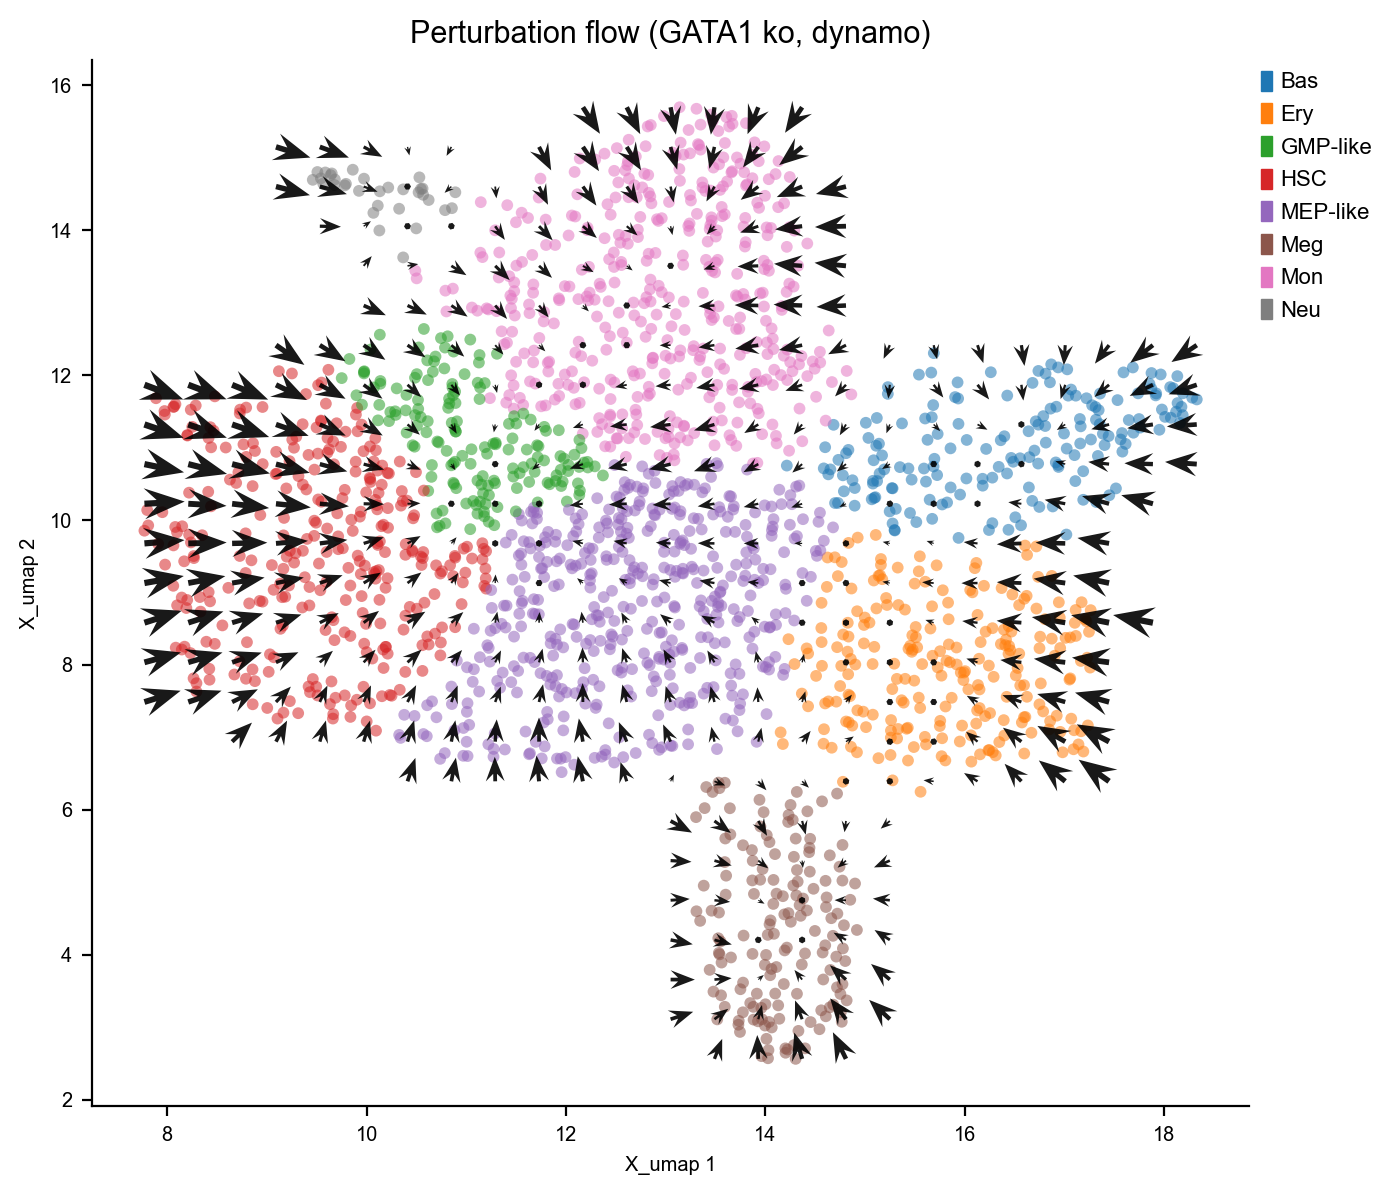

In [9]:
fig, ax = ov.pl.perturb_quiver(adata, result, cluster_col='cell_type')
plt.show()

## 4. Score perturbations along the hematopoietic potential

The reference object contains `pca_ddhodge_potential`, a diffusion potential
estimated by dynamo on the vector field. It can be supplied as pseudotime
to `perturbation_score()`.

For the supplied pseudotime, **PS > 0** indicates a shift toward increasing
pseudotime, and **PS < 0** indicates the opposite direction. A differentiation
interpretation depends on the direction and biological meaning of that pseudotime.

In [10]:
ps = result.perturbation_score(adata, pseudotime='pca_ddhodge_potential')

df = pd.DataFrame({'PS': ps.values, 'cell_type': adata.obs['cell_type'].values})
summary = df.groupby('cell_type', observed=True)['PS'].agg(['mean', 'count'])
summary.sort_values('mean')

,mean,count
Bas,-0.119944,177
Mon,-0.088418,423
Ery,-0.064320,234
MEP-like,-0.062904,457
GMP-like,-0.032834,161
HSC,-0.006769,309
Meg,0.025509,154
Neu,0.040578,32


## 5. Rank gene responses by cell type

With `group='cell_type'`, dynamo ranks genes marked `use_for_dynamics`.
Each observed group has one column in each of two tables:

- `adata.uns[result.meta['rank_key']]`: descending mean signed response.
- `adata.uns['rank_abs_' + result.meta['perturbation_key']]`: descending
  mean absolute per-cell response, including genes with large negative responses.

The absolute table uses `mean(abs(delta))`, not `abs(mean(delta))`, so
opposing responses across cells do not cancel. The signed table retains
response direction. With `copy=True`, read these tables from
`result.adata_perturbed.uns`.

In [11]:
rank_df = adata.uns[result.meta['rank_key']]
absolute_rank_df = adata.uns['rank_abs_' + result.meta['perturbation_key']]
print('groups:', absolute_rank_df.columns.tolist())
absolute_rank_df.head(8)

groups: ['Bas', 'Ery', 'GMP-like', 'HSC', 'MEP-like', 'Meg', 'Mon', 'Neu']


,Bas,Ery,GMP-like,HSC,MEP-like,Meg,Mon,Neu
0,HBD,HBB,GSTP1,HBD,HBD,HBG2,HBD,HLA-DPB1
1,HBB,HBD,HBD,GSTP1,HBB,PLEK,HBB,AL035078.1
2,AL035078.1,AL035078.1,FCER1A,FCER1A,GSTP1,PF4,AL035078.1,LYZ
3,TPSAB1,FBL,FGFR1,AL035078.1,AL035078.1,HBD,GSTP1,MYL6
4,HPGD,TOP2A,AL035078.1,HBB,FCER1A,THBS1,MPO,PKM
5,LAPTM5,FGFR1,HDC,FGFR1,FGFR1,PTGS1,FGFR1,S100A4
6,CKAP4,LAPTM5,ITGA2B,HDC,MYL6,PPBP,EEF1D,FTL
7,FGFR1,OAZ1,HBB,ITGA2B,FBL,ITGA2B,PKM,PSAP


## 6. Vector-field knockout: `vf_ko=True`

`vf_ko=True` additionally evaluates dynamo's native KO vector field and
writes `velocity_pca_KO` / `velocity_umap_KO`, with corresponding coordinate
copies `X_pca_KO` / `X_umap_KO`. The baseline PCA and vector field are preserved.

KO velocities are stored separately. `result.delta_X`,
`result.trajectory_shift`, group rankings and shared downstream plots
retain the interpretation of the selected perturbation method (Jacobian by default). Callable KO models and
fate integration require separate use of dynamo's native KO interface.

The option applies to `mode='ko'`. KD/OE emit a warning and do not perform
the additional vector-field knockout. Use `copy=True` for independent
results, or distinct output keys for multiple runs on one AnnData.

Active KO reserves `X_pca_KO`, `velocity_pca_KO`, `X_<emb_basis>_KO` and
`velocity_<emb_basis>_KO` in `obsm`, and `pearson_transition_matrix` in `obsp`.
Custom perturbation output keys that collide with these names raise `ValueError`
before computation. Use distinct names such as `gata1_vf_ko_response` and
`gata1_vf_ko_transitions`.

The following example uses `copy=True` and reads KO outputs from
`result_ko.adata_perturbed`.

Native KO requires the default PCA coordinates/loadings/means and `VecFld_pca`. A cached Jacobian or custom PCA alone is insufficient; prepare the default KO model or leave `vf_ko=False`.


In [12]:
result_ko = ov.single.perturb(
    adata, target='GATA1', mode='ko', backend='dynamo', copy=True,
    backend_kwargs={'vf_ko': True, 'group': 'cell_type',
                    'add_delta_Y_key': 'gata1_vf_ko_response'},
)
print('KO velocity keys written:', result_ko.meta['vf_ko_keys'])
print('velocity_umap_KO in result:',
      'velocity_umap_KO' in result_ko.adata_perturbed.obsm)

|-----> In silico perturbation of single-cells and prediction of cell fate after perturbation...


|-----> Retrive X_pca, PCs, pca_mean...


|-----> Calculate perturbation effect matrix via \delta Y = J \dot \delta X....


|-----> project the pca perturbation vector to low dimensional space....


|-----> [projecting velocity vector to low dimensional embedding] in progress: 1.0272%

...

|-----> [projecting velocity vector to low dimensional embedding] in progress: 100.0000%

|-----> [projecting velocity vector to low dimensional embedding] completed [0.1696s]


|-----> method arg is None, choosing methods automatically...


|-----------> method kd_tree selected



╭─ SUMMARY: KO ──────────────────────────────────────────────────────╮
│  Duration: 0.8338s                                                 │
│  Shape:    1,947 x 1,956 (Unchanged)                               │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● UNS    │ ✚ grid_velocity_umap_KO                                │
│                                                                    │
│  ● OBSP   │ ✚ pearson_transition_matrix (sparse matrix, 1947x1947) │
│                                                                    │
│  ● OBSM   │ ✚ X_pca_KO (array, 1947x30)                            │
│           │ ✚ X_umap_KO (array, 1947x2)                            │
│           │ ✚ velocity_pca_KO (array, 1947x30)                     │
│           │ ✚ velocity_umap_KO (array, 1947x2)                     │
│    

## 7. Starting from raw counts

Velocity estimation requires `spliced`/`unspliced` layers or metabolic-labeling
`new`/`total` layers with sampling times available to dynamo. An expression
matrix in `adata.X` alone is insufficient; use `backend='sctenifoldknk'` for
expression-only data.

Set `auto_pipeline=True` to prepare missing PCA, dynamics, neighbors,
embedding and vector-field outputs. `copy=True` preserves the input counts:

```python
result = ov.single.perturb(
    adata, target='GATA1', mode='ko', backend='dynamo', copy=True,
    backend_kwargs={'auto_pipeline': True},
)
```

The automatic Monocle preprocessor preserves `adata.var_names` and includes
targets among PCA features without downloading gene annotations. Match
`target` to the input gene identifiers. For Ensembl-indexed data, use Ensembl
IDs; convert identifiers explicitly before fitting if gene symbols are needed.

When a learned vector field exists, the automatic pipeline reuses it and
fills missing prerequisites. For kinetic labeling data with separate
spliced/unspliced and new/total measurements, dynamics estimation uses
`est_method='twostep'`; other layouts retain dynamo's defaults. Inspect
`result.meta['dynamics_est_method']` or `adata.uns['dynamics']` for the actual
estimator. To choose another model, prepare and fit the data explicitly.

### Prepare the model explicitly

For raw data indexed by gene symbols, the corresponding preparation is:

```python
import dynamo as dyn

preprocessor = dyn.pp.Preprocessor(
    convert_gene_name_function=lambda data: data,
    gene_append_list=['GATA1'],
)
preprocessor.preprocess_adata(adata, recipe='monocle')
dynamics_kwargs = {}
preprocessing = adata.uns.get('pp', {})
if (preprocessing.get('experiment_type') == 'kin'
        and preprocessing.get('has_splicing')
        and not preprocessing.get('splicing_labeling')):
    dynamics_kwargs['est_method'] = 'twostep'
dyn.tl.dynamics(adata, **dynamics_kwargs)
dyn.tl.neighbors(adata, X_data=adata.obsm['X_pca'], basis='pca')
dyn.tl.reduceDimension(
    adata, X_data=adata.obsm['X_pca'], basis='pca',
    n_pca_components=adata.obsm['X_pca'].shape[1], reduction_method='umap',
)
dyn.tl.cell_velocities(adata, basis='pca', enforce=True)
dyn.vf.VectorField(adata, basis='pca')
result = ov.single.perturb(adata, target='GATA1', mode='ko', backend='dynamo')
```

This preparation changes `adata` in place. Use a copy to retain raw counts.
When both `VecFld_pca` and a base GRN exist, `backend='auto'` selects dynamo;
choose `backend='cell_oracle'` to use the GRN.

### Backend kwargs

| Parameter | Default | Meaning |
|---|---|---|
| `emb_basis` | `'umap'` | Embedding for projection; the automatic pipeline can prepare it |
| `perturb_mode` | `'raw'` | Expression level; `'z_score'` converts using the PCA-reconstructed distribution |
| `perturbation_method` | `'j_delta_x'` | `j_delta_x`, `j_x_prime`, `j_jv`, `f_x_prime`, `f_x_prime_minus_f_x_0`; dynamo's spelling `pertubation_method` is also accepted |
| `group` | `None` | `adata.obs` column for per-group response ranking |
| `vf_ko` | `False` | Additional native KO velocities for `mode='ko'` |
| `auto_pipeline` | `False` | Prepare missing prerequisites on the result object |
| `add_delta_Y_key` | `'<method>_perturbation'` | Response key in `layers` / `obsm`, used for `delta_X` and ranking |
| `add_transition_key` | `'perturbation_transition_matrix'` | Transition key in `obsp` |
| `add_velocity_key` | `'velocity_<emb_basis>_perturbation'` | Arrow key in `obsm` |
| `add_embedding_key` | `'X_<emb_basis>_perturbation'` | Copied embedding key in `obsm` |

`auto_pipeline`, `vf_ko` and `group` control preparation, additional KO and
ranking. Other options are passed to `dynamo.pd.perturbation`; unknown names
raise `TypeError`. The supplied `backend_kwargs` dictionary is unchanged.
`projection_method='transform'` returns no transition matrix; its native
baseline-velocity limitation is described below.

All targets must have `use_for_pca=True`; multi-target values are aligned
in PCA gene order. The selected input layer must use the PCA model's
expression scale.

### Native parameter access and compatibility

The backend adapts `dynamo.pd.perturbation`; it does not replace the entire
dynamo API. `target` corresponds to native `genes`. Without an explicit
`expression`, KO/KD/OE generate the requested levels described above.
A finite scalar or one value per unique target can override those levels:

```python
result_custom = ov.single.perturb(
    adata, target=['GATA1', 'HBB'], backend='dynamo', copy=True,
    backend_kwargs={'expression': [0.0, 1.5], 'perturb_mode': 'raw',
                    'cells': [0, 1, 2]},
)
```

Values follow the caller's target order and use native `raw` or `z_score`
units. An explicit z-score is passed directly; automatic KO/KD/OE levels
are converted from expression units. `mode` remains the result label and
controls additional `vf_ko`; inspect `meta['expression_source']` and
`meta['expression']` for the actual requested levels.

| Native options | Behavior |
|---|---|
| `cells` | Restrict the perturbation to selected cell indices |
| `pca_key`, `PCs_key`, `pca_mean_key`, `X_pca` | Select prepared PCA coordinates, loadings and means; loadings/means may be arrays, coordinates use `X_pca` for arrays |
| `basis`, `jac_key` | Select the vector field and a prepared Jacobian |
| `delta_t`, `J_jv_delta_t` | Native response scales; `J_jv_delta_t` applies to `j_jv` |
| `projection_method` | Native projection, including `fp`, `pearson`, `cosine` and `kmc`; see the transform limitation below |
| `zero_perturb_genes_vel` | Zero target response columns only when native PCA and full-gene indices agree |

Custom PCA inputs are reused without requiring default PCA keys. With
explicit `X_pca`, omitted loading/mean options resolve to `PCs` / `pca_mean`.
The automatic pipeline fits the default PCA model; prepare a custom model's
missing prerequisites explicitly instead of requesting an automatic refit.

Dynamo-release 1.5.3 has several native limitations:

- Its precomputed `delta_Y` path leaves PCA loadings undefined. This option
  raises `NotImplementedError` here; use target/expression perturbations.
- `pca_key` must be a string. Pass coordinate arrays as `X_pca` instead.
- Native target-zeroing uses PCA-local indices on full-gene response layers.
  The wrapper rejects `zero_perturb_genes_vel=True` if those indices differ,
  preventing unrelated genes from being silently zeroed.
- `projection_method='transform'` can reload baseline velocities rather than
  the perturbation response. It emits a warning and returns no transition
  matrix. Prefer `fp` for perturbation-driven transitions and arrows.

`group` and `vf_ko` provide the ranking and KO defaults shown in this tutorial.
For custom ranking aggregation, gene selection or output prefixes, call
`dynamo.pd.rank_perturbation_genes` directly. For custom KO vector fields,
output names, velocity differences, model persistence or callable KO models,
use `dynamo.pd.KO` directly. Fate integration remains a separate native workflow.

### Full raw-data example

The [raw hematopoiesis file](https://stacks.stanford.edu/file/sh696dv4420/hematopoiesis_raw.h5ad)
contains 1,947 cells and 26,193 genes, with spliced/unspliced and new/total
counts and sampling times in `obs['time']`. Its gene index contains Ensembl
IDs. Download it to the working directory or adjust the path below. The
example starts a fresh AnnData with every input cell and gene:

```python
import anndata as ad

source = ad.read_h5ad('hematopoiesis_raw.h5ad')
raw = ad.AnnData(
    X=source.X.copy(), obs=source.obs.copy(), var=source.var.copy(),
    layers={key: source.layers[key].copy()
            for key in ('spliced', 'unspliced', 'new', 'total')},
)
result_raw = ov.single.perturb(
    raw, target='ENSG00000102145', mode='ko', backend='dynamo',
    backend_kwargs={'auto_pipeline': True, 'group': 'cell_type'},
)
print(result_raw.delta_X.shape, result_raw.trajectory_shift.shape)
print(result_raw.meta['dynamics_est_method'])
```

Native preprocessing still performs quality control and PCA feature
selection. Use `mode='kd'` or `mode='oe'` with `fold_change` for knockdown
or over-expression. With `mode='ko'`, add `vf_ko=True` to request KO velocities.

Responses depend on the input data, preprocessing and vector-field fit.
Refitting may change response amplitudes and gene rankings; interpret them
with cell-type annotations, experimental design and biological evidence.

## 8. Frequently asked questions

### Why is dynamo selected automatically?

`VecFld_pca` takes priority over a base GRN in `backend='auto'`. Select
`backend='cell_oracle'` or `backend='sctenifoldknk'` explicitly to use those models.

### Why is a target missing or excluded from PCA?

Match `target` exactly to `adata.var_names`, including Ensembl IDs when
applicable. A fitted PCA model must include all targets in `use_for_pca`.
If a target is excluded, refit PCA and the vector field with that target
included; changing the feature flag alone does not update the fitted model.

### Can expression counts alone run the automatic pipeline?

No. Provide splicing or metabolic-labeling count layers and the sampling
information required by the experimental design. For expression-only data,
select `backend='sctenifoldknk'`. With `auto_pipeline=False`, missing model
prerequisites raise a `RuntimeError` listing preparation steps.

### Where are predicted expression and GRN outputs?

Dynamo returns model responses in `delta_X` and the named response layer.
It does not replace `.X` with predicted counts or reconstruct a GRN.
`grn` / `grn_base` are `None`, and `delta_grn` is empty.

### Why is `log2_fc` sometimes `NaN`?

`mean_pert` is baseline mean plus signed model response and may be negative.
The response is retained, but its fold-change summary is undefined when
either mean is negative or non-finite. Rank such genes by `delta` or the
absolute-response group table instead.

### Why do group tables omit genes or change the ranking?

Native rankings include `use_for_dynamics` genes. Signed rankings use the
mean response; absolute rankings use the mean absolute per-cell response.
These summaries answer different questions and can order genes differently.

### How can multiple runs be retained?

Use `copy=True` and read outputs from each result's `adata_perturbed`, or
choose distinct `add_*` keys on a shared object. Active `vf_ko` reserves the
native KO output names described above; conflicting keys raise `ValueError`.

### Why is the transition matrix missing, or KO ignored?

`projection_method='transform'` produces no transition matrix and can use baseline velocities in 1.5.3; prefer `fp` for perturbation-driven arrows.
`vf_ko=True` adds native KO velocities only in KO mode; KD/OE warn and skip
that additional calculation. Shared response and transition outputs remain
the selected perturbation results (Jacobian by default).

## Summary

- KO/KD/OE responses and the native transition matrix are available through `PerturbResult`.
- The baseline `.X` is preserved; read `delta_X` or the named response layer for model responses. GRN outputs are unavailable for dynamo.
- Shared response analyses include cell-type transitions, embedding arrows and perturbation scores. Additional KO velocities are stored separately.
- Automatic dispatch selects dynamo for `VecFld_pca`, CellOracle for a base GRN, and scTenifoldKnk otherwise.
- Automatic fitting requires count layers and sampling information compatible with the experimental design; gene identifiers and expression scales must match the model.